# Đánh giá dự báo PM2.5 từ t+1 đến t+4

So sánh checkpoint SE-LSTM của lượt `pm_hanoi_2`, seed 42, với hai baseline trên cùng toàn bộ tập test. Mỗi cửa sổ đóng góp một cặp dự báo–quan sát cho mỗi mốc từ **t+1** đến **t+4**.

- **Persistence:** dùng PM2.5 của giờ gần nhất cho cả bốn mốc.
- **Seasonal naive:** dùng PM2.5 của giờ tương ứng ngày hôm trước cho từng mốc.

Chọn kernel của môi trường `aqi_forecast` rồi bấm **Run All** để cập nhật bảng và hình.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
candidates = (cwd, cwd / "HN_PM25_forecasting", *cwd.parents)
root = next((path for path in candidates if (path / "configs/common.yaml").is_file()), None)
if root is None:
    raise FileNotFoundError("Mở notebook từ thư mục HN_PM25_forecasting hoặc workspace của dự án.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.baselines import persistence_forecast, seasonal_naive_forecast
from src.data_pipeline import load_prepared_split
from src.metrics import compute_forecast_metrics
from src.preprocessing import inverse_targets, load_scalers
from src.utils import load_config


In [2]:
import tensorflow as tf

from scripts.evaluate import predict_batches
from src.utils import dataset_fingerprint, read_json, sha256

checkpoint = root / "runs/se_lstm/pm_hanoi_2/seed_42/best.keras"
if not checkpoint.is_file():
    raise FileNotFoundError(f"Không tìm thấy checkpoint tại {checkpoint}")
metadata = read_json(checkpoint.parent / "run_metadata.json")
if sha256(checkpoint) != metadata["checkpoint_sha256"]:
    raise ValueError("Checkpoint đã thay đổi so với metadata của lần train.")

# Dùng đúng bộ dữ liệu của checkpoint, kể cả khi cấu hình mặc định đã đổi.
processed_dir = Path(metadata["processed_dir"])
if not processed_dir.is_dir():
    processed_dir = load_config(root / "configs/common.yaml").processed
if dataset_fingerprint(processed_dir) != metadata["dataset_fingerprint"]:
    raise ValueError("Dữ liệu hiện tại khác dữ liệu được ghi trong metadata của model.")

X, y = load_prepared_split(processed_dir, "test")
scalers = load_scalers(processed_dir / "scalers.json")
X_raw = scalers.x.inverse_transform(X.reshape(-1, X.shape[-1])).reshape(X.shape)
y_raw = inverse_targets(y, scalers)

with tf.device("/CPU:0"):
    model = tf.keras.models.load_model(checkpoint, compile=False)
    model_forecasts = inverse_targets(predict_batches(model, X), scalers)

model_name = metadata["model_name"].replace("_", "-").upper()
model_label = f"{model_name} (seed {metadata['seed']})"
print(f"Checkpoint: {checkpoint.relative_to(root)}")
print(f"Dữ liệu: {processed_dir.name}")
print(f"{model_label}: {len(y_raw):,} cửa sổ test, {y_raw.shape[1]} mốc dự báo mỗi cửa sổ.")

Checkpoint: runs\se_lstm\pm_hanoi_2\seed_42\best.keras
Dữ liệu: pm25_24x4_hanoi_aqi
SE-LSTM (seed 42): 388 cửa sổ test, 4 mốc dự báo mỗi cửa sổ.


## Kết quả tổng hợp và theo mốc dự báo

Bảng đầu gộp cả bốn mốc dự báo trên tập test. Bảng thứ hai tách kết quả theo từng mốc. MAE và RMSE có đơn vị µg/m³.

In [3]:
predictions = {
    model_label: model_forecasts,
    "Persistence": persistence_forecast(X_raw),
    "Seasonal naive": seasonal_naive_forecast(X_raw),
}
metrics_by_model = {
    name: compute_forecast_metrics(y_raw, prediction)
    for name, prediction in predictions.items()
}
scores = {name: metrics["per_horizon"] for name, metrics in metrics_by_model.items()}
horizon_hours = range(1, y_raw.shape[1] + 1)
metric_labels = {
    "mae": "MAE (µg/m³)",
    "rmse": "RMSE (µg/m³)",
    "smape_pct": "sMAPE (%)",
    "r2": "R²",
    "n_pairs": "Số cặp",
}
overall = pd.DataFrame.from_dict(
    {name: metrics["overall"] for name, metrics in metrics_by_model.items()},
    orient="index",
).rename_axis("Mô hình")
display(overall[list(metric_labels)].sort_values("mae").rename(columns=metric_labels).round(3))

table = pd.DataFrame([
    {"Mốc": f"t+{hour}", "Mô hình": name, **metrics[hour - 1]}
    for hour in horizon_hours
    for name, metrics in scores.items()
])
display(
    table.set_index(["Mốc", "Mô hình"])[list(metric_labels)]
    .rename(columns=metric_labels)
    .round(3)
)

,MAE (µg/m³),RMSE (µg/m³),sMAPE (%),R²,Số cặp
Mô hình,,,,,
SE-LSTM (seed 42),9.583,17.010,33.772,0.172,1552
Persistence,10.985,19.792,35.782,-0.121,1552
Seasonal naive,14.251,21.417,50.815,-0.313,1552


MAE (µg/m³)  RMSE (µg/m³)  sMAPE (%)     R²  Số cặp
Mốc Mô hình                                                               
t+1 SE-LSTM (seed 42)        6.450        12.211     23.004  0.581     388
    Persistence              6.362        12.834     21.303  0.537     388
    Seasonal naive          14.674        21.891     51.044 -0.347     388
t+2 SE-LSTM (seed 42)        8.877        15.748     31.472  0.293     388
    Persistence              9.934        17.556     32.728  0.121     388
    Seasonal naive          14.257        21.406     50.598 -0.307     388
t+3 SE-LSTM (seed 42)       10.809        18.549     37.957  0.009     388
    Persistence             12.761        21.718     41.289 -0.359     388
    Seasonal naive          14.035        21.194     50.599 -0.294     388
t+4 SE-LSTM (seed 42)       12.195        20.402     42.653 -0.210     388
    Persistence             14.886        24.945     47.810 -0.809     388
    Seasonal naive          14.037        21.170     51.018 -0.303     388

## Dự báo và quan sát trên toàn bộ tập test

Mỗi hình dùng cùng thang đo PM2.5 cho model đã chọn và hai baseline. Trục ngang là thứ tự các cửa sổ test hợp lệ theo thời gian. Notebook xuất ba file PNG cho t+2, t+3 và t+4.

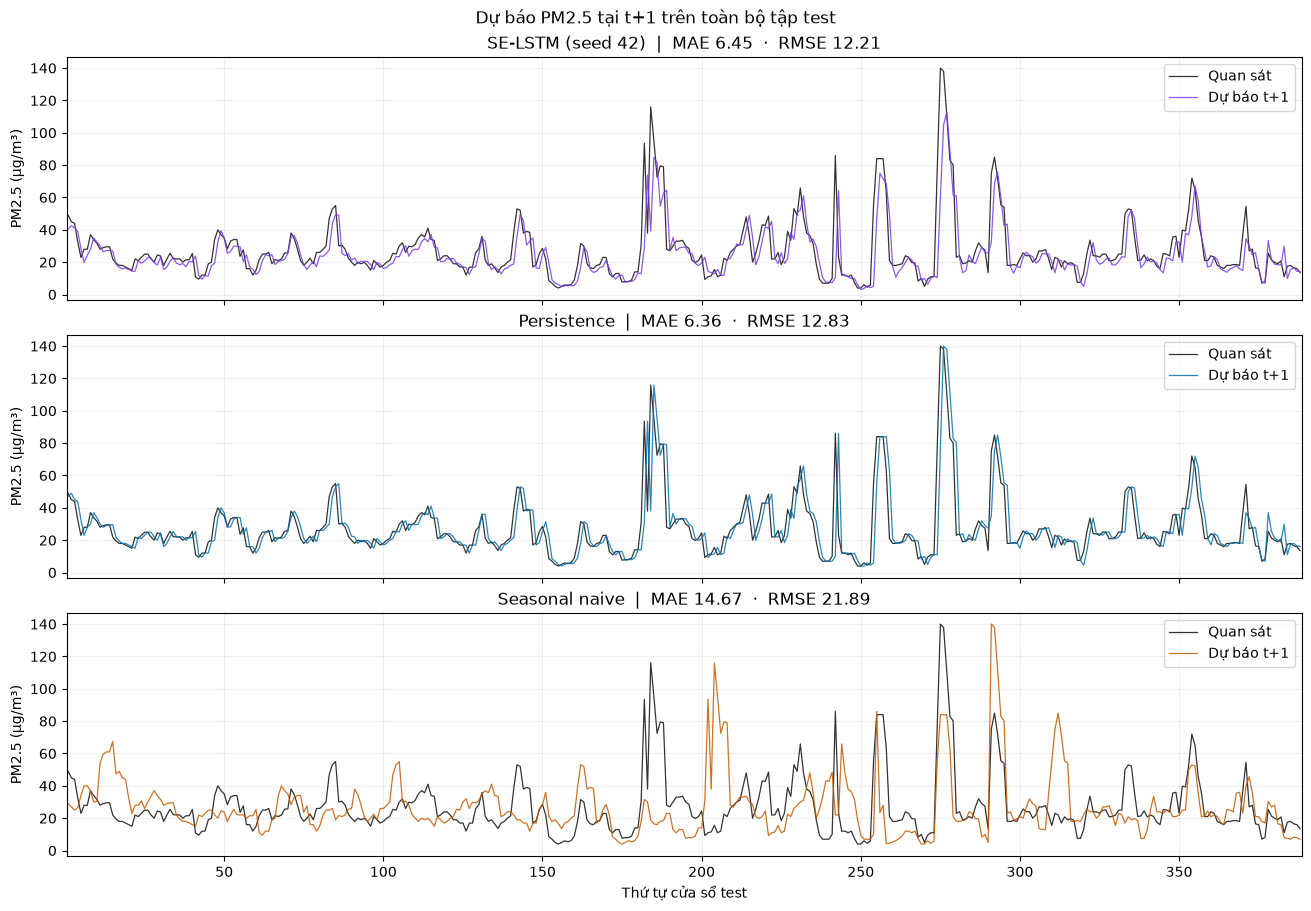

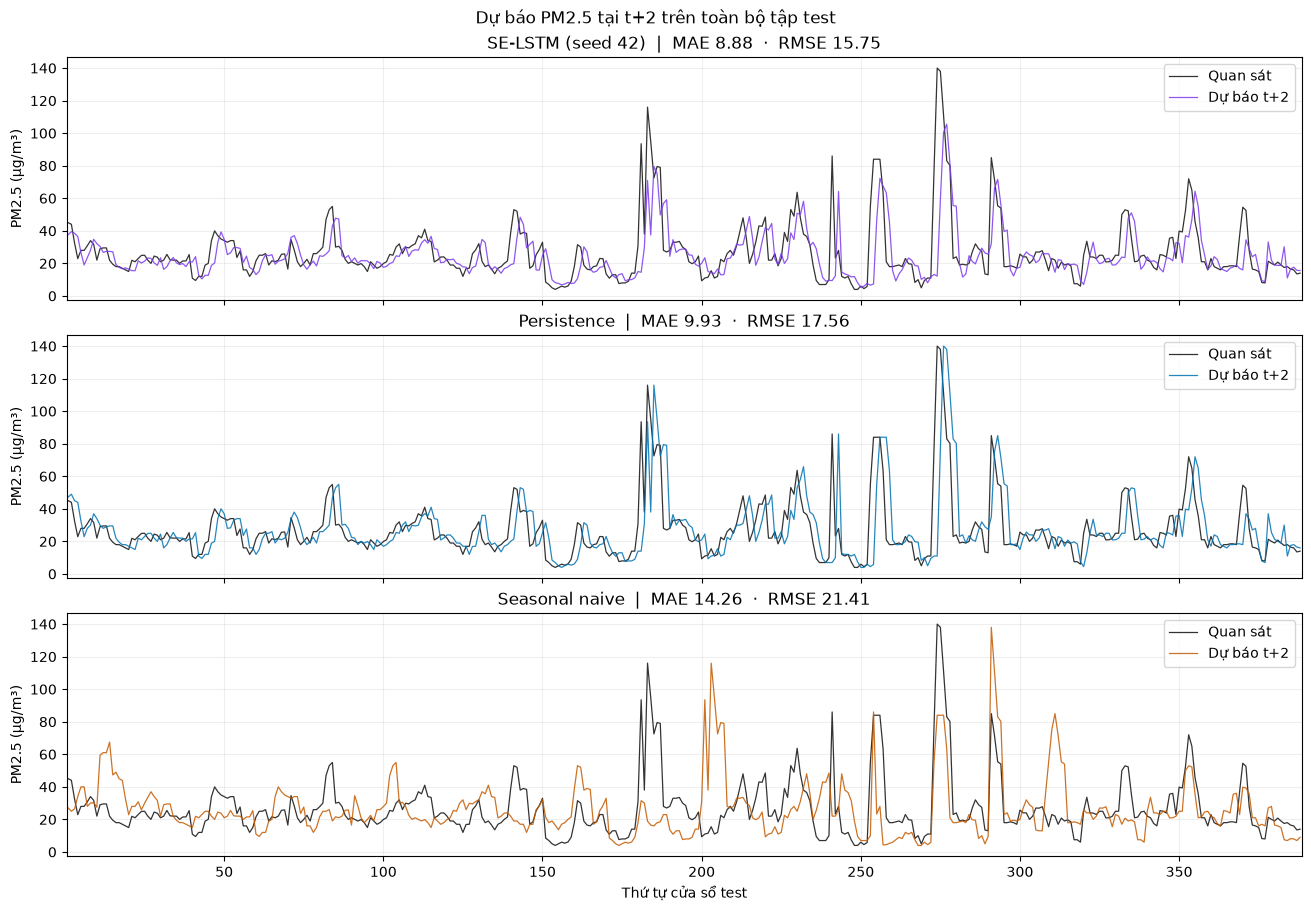

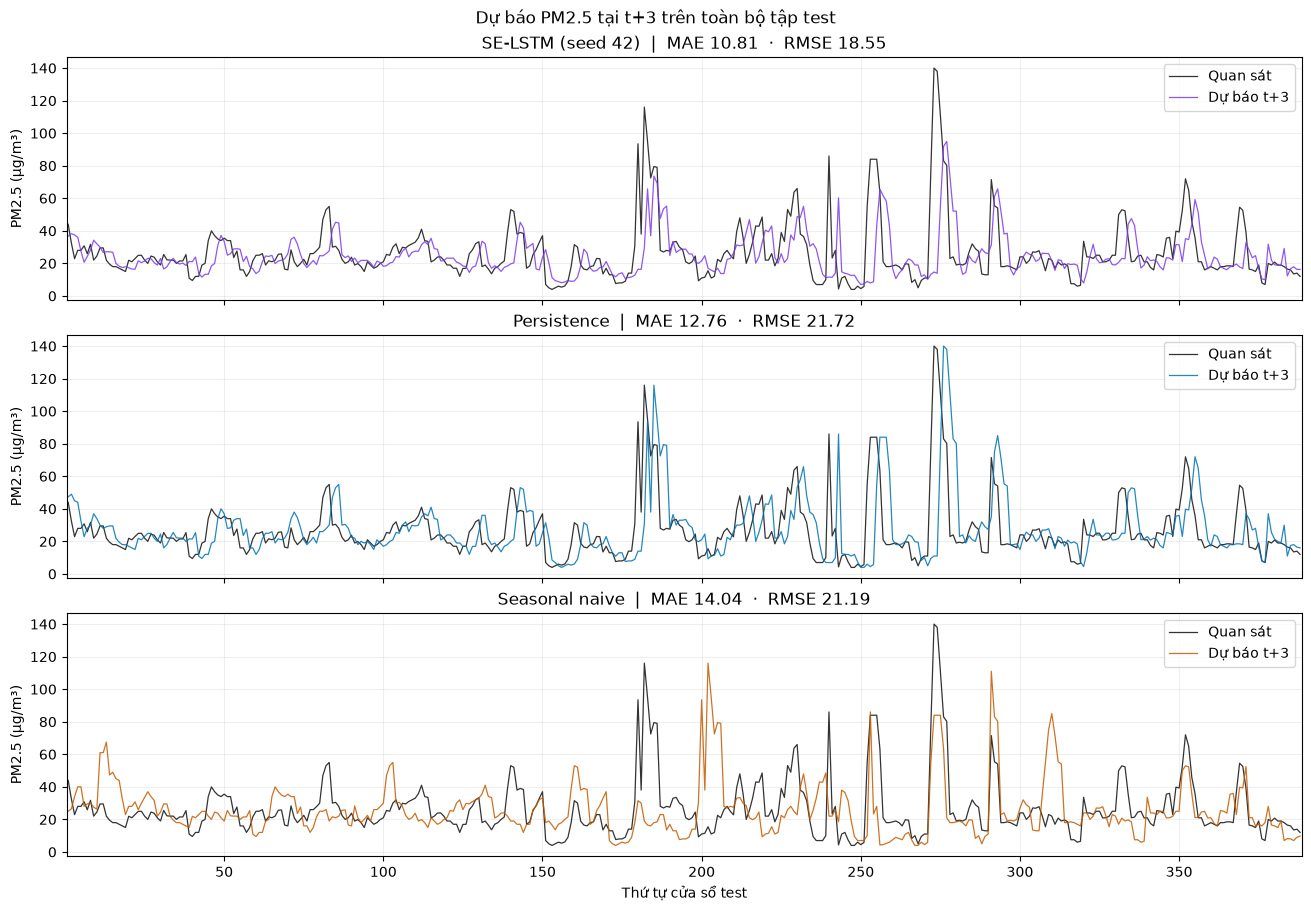

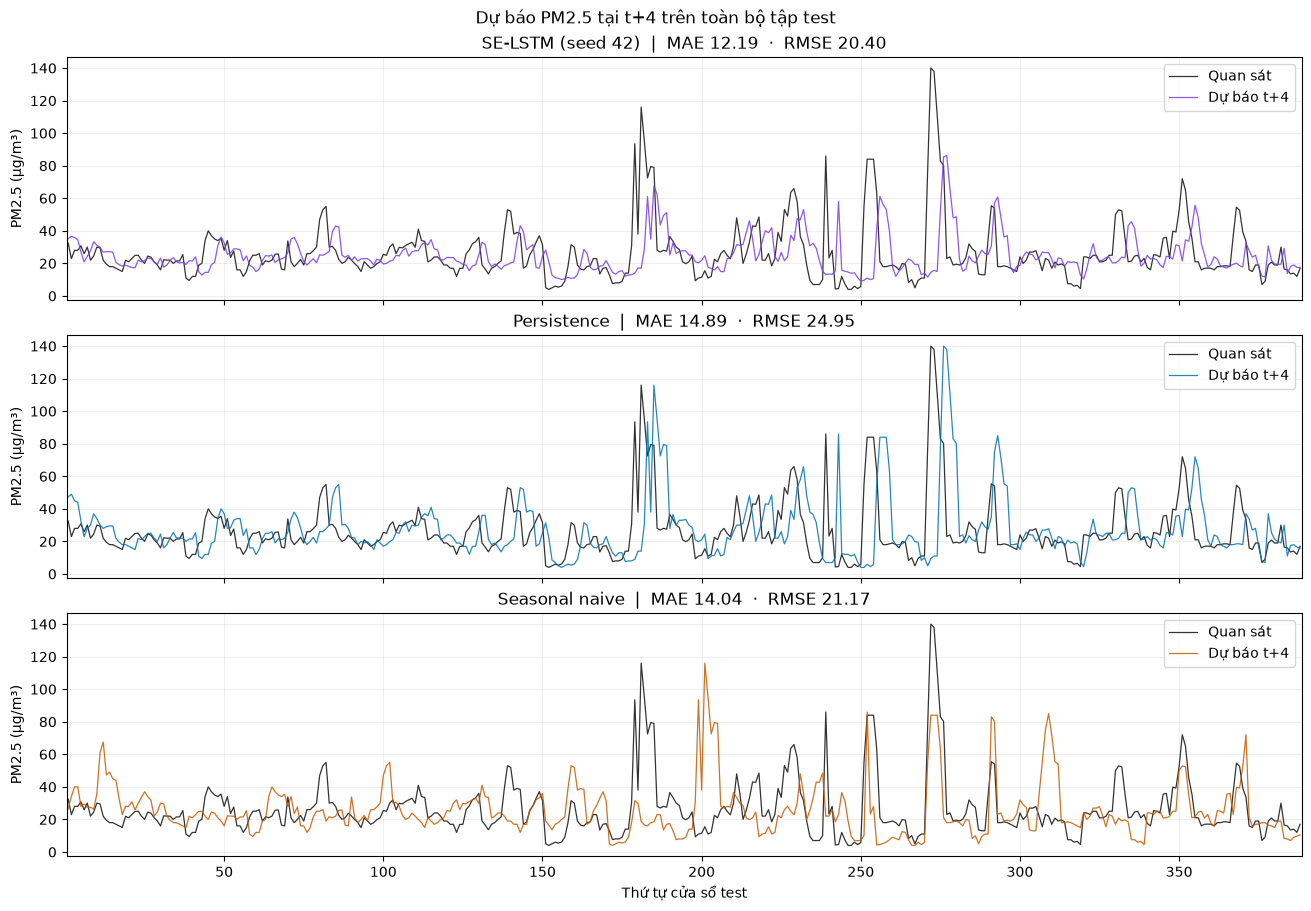

In [4]:
def plot_horizon(hour):
    column = hour - 1
    observed = y_raw[:, column]
    windows = range(1, len(observed) + 1)
    figure, axes = plt.subplots(
        len(predictions), 1, figsize=(13, 9), sharex=True, sharey=True,
        layout="constrained"
    )
    figure.suptitle(f"Dự báo PM2.5 tại t+{hour} trên toàn bộ tập test")
    colors = ("#7c3aed", "#0072b2", "#c45a00")
    for axis, (name, prediction), color in zip(axes, predictions.items(), colors):
        axis.plot(windows, observed, color="#333333", linewidth=0.9, label="Quan sát")
        axis.plot(
            windows, prediction[:, column], color=color, linewidth=0.9, alpha=0.85,
            label=f"Dự báo t+{hour}"
        )
        metrics = scores[name][column]
        axis.set(
            title=f"{name}  |  MAE {metrics['mae']:.2f}  ·  RMSE {metrics['rmse']:.2f}",
            ylabel="PM2.5 (µg/m³)"
        )
        axis.grid(alpha=0.2)
        axis.legend(loc="upper right")

    axes[-1].set(xlabel="Thứ tự cửa sổ test", xlim=(0.5, len(observed) + 0.5))
    return figure


plot_horizon(1)
plt.show()

output_dir = root / "visualizations" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)
for hour in (2, 3, 4):
    figure = plot_horizon(hour)
    filename = f"{metadata['model_name']}_vs_baselines_test_t_plus_{hour}.png"
    output = output_dir / filename
    figure.savefig(output, dpi=180, facecolor="white")
    plt.show()